# Vision-controlled 3D-printed hand: complete AI notebook (tracking, calibration, detection, grasp baseline, dataset)

One notebook for the whole AI part of the project (4 active fingers: **thumb, index, middle, ring**, 1 DOF each). It merges the MediaPipe notebook and the object-detection notebook, and **saves everything you need for the presentation** in a `slide_evidence` folder, with a final cell that prints the numbers for the slide.

**How to use**
1. Chrome or Edge, allow the camera. Cells that use the webcam (or ask for files) wait for you: that is normal.
2. Run the cells in order. If you get a numpy or import error after the install cell: Runtime > Restart session, then run again from the second cell.
3. Each team member should run parts 3 to 5 with their own hand (change `PERSON` in part 1). That gives you the "works on different hands" result.
4. Run part 10 at the end: it prints the slide text and downloads `slide_evidence.zip` and `dataset.zip`.

| Part | Content | Needs |
|---|---|---|
| 1 | Setup and configuration | |
| 2 | Quick check: hand tracking on a photo | webcam |
| 3 | **Calibration of a person** (6 s, open hand then fist) | webcam |
| 4 | Tracking + **teleoperation demo** (webcam clip mirrored by a virtual hand) | webcam |
| 5 | **Does calibration help?** default vs. calibrated vs. automatic | part 4 |
| 6 | **Object detection** (YOLO) and test on your object photos | photos |
| 7 | **Rule-based grasp baseline** (object to finger curls to servo angles) | |
| 8 | **Full pipeline demo** (image to detection to grasp to servo message) | part 6 |
| 9 | **Dataset** (object images and teleoperation episodes) | webcam |
| 10 | **Results summary for the slide** and downloads | |
| 11 | Optional: live webcam stream | webcam |

**Where the slide material is saved (folder `slide_evidence`)**

| File | Use on the slides |
|---|---|
| `01_hand_skeleton.jpg` | Screenshot: hand tracked by MediaPipe |
| `02_mirror_open.jpg`, `02_mirror_closed.jpg`, `02_mirror_clip.mp4` | Teleoperation demo: tracked hand + virtual robot hand |
| `03_finger_curls.png` | Plot of the 4 finger curls over time |
| `04_yolo_*.jpg`, `04_yolo_results.csv` | Object detection screenshots and results table |
| `05_grasp_presets_gallery.png`, `05_grasp_presets.csv` | Rule-based grasp baseline |
| `06_pipeline_*.jpg` | Full pipeline demo screenshots |
| `07_calibration_comparison.png`, `07_calibration_comparison.csv` | Calibration result |
| `slide_summary.md` | **The text and numbers to copy into slide 5** |

## 1. Setup and configuration

In [ ]:
!pip install -q ultralytics mediapipe

In [ ]:
import os, time, urllib.request
from base64 import b64decode, b64encode

import numpy as np
import cv2
import pandas as pd
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

from IPython.display import display, Javascript, HTML
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow

print("MediaPipe version:", mp.__version__)

MODEL_URL = ("https://storage.googleapis.com/mediapipe-models/"
             "hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task")
MODEL_PATH = "hand_landmarker.task"
if not os.path.exists(MODEL_PATH):
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)
print("Model ready:", MODEL_PATH, f"({os.path.getsize(MODEL_PATH)/1e6:.1f} MB)")

import json, glob, shutil, subprocess
from collections import deque
import matplotlib.pyplot as plt
from google.colab import files

MediaPipe version: 1.2.2
Model ready: hand_landmarker.task (7.8 MB)


In [ ]:
def make_detector(mode="IMAGE", num_hands=1, det_conf=0.5, track_conf=0.5):
    """mode: 'IMAGE' for single photos, 'VIDEO' for frame sequences (uses tracking, faster and smoother)."""
    running_mode = {"IMAGE": vision.RunningMode.IMAGE,
                    "VIDEO": vision.RunningMode.VIDEO}[mode]
    options = vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MODEL_PATH),
        running_mode=running_mode,
        num_hands=num_hands,
        min_hand_detection_confidence=det_conf,
        min_hand_presence_confidence=track_conf,
        min_tracking_confidence=track_conf,
    )
    return vision.HandLandmarker.create_from_options(options)


def detect_bgr(detector, bgr, timestamp_ms=None):
    """Run the detector on an OpenCV (BGR) image. Pass timestamp_ms for VIDEO mode."""
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    if timestamp_ms is None:
        return detector.detect(mp_img)
    return detector.detect_for_video(mp_img, timestamp_ms)


# The 21 landmarks: 0 wrist | 1-4 thumb | 5-8 index | 9-12 middle | 13-16 ring | 17-20 pinky
HAND_CONNECTIONS = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
                    (9,13),(13,14),(14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]

def draw_hands(img, result, line_color=(0, 255, 0), pt_color=(0, 0, 255)):
    """Draw the skeleton on img (works on 3-channel and 4-channel images)."""
    h, w = img.shape[:2]
    for lms in result.hand_landmarks:
        pts = [(int(l.x * w), int(l.y * h)) for l in lms]
        for a, b in HAND_CONNECTIONS:
            cv2.line(img, pts[a], pts[b], line_color, 2)
        for p in pts:
            cv2.circle(img, p, 4, pt_color, -1)
    return img

In [ ]:
# ===================== PROJECT CONFIGURATION (edit here) =====================
PERSON = "person1"      # EDIT: name of the person in front of the camera (used for the profile and the dataset)

ACTIVE_FINGERS = ["thumb", "index", "middle", "ring"]     # the 4 fingers of the real hand (1 servo each)

# Landmark triplets (a, b, c): angle measured at b. 'mcp' = base joint, 'pip' = middle joint
FINGER_JOINTS = {
    "thumb":  {"mcp": (1, 2, 3),   "pip": (2, 3, 4)},
    "index":  {"mcp": (0, 5, 6),   "pip": (5, 6, 7)},
    "middle": {"mcp": (0, 9, 10),  "pip": (9, 10, 11)},
    "ring":   {"mcp": (0, 13, 14), "pip": (13, 14, 15)},
    "pinky":  {"mcp": (0, 17, 18), "pip": (17, 18, 19)},
}

# HUMAN side: flexion in degrees (0 = straight finger) counted as "open" and "closed".
# These defaults are a fallback that works without any setup (the thumb moves less than the other fingers: a guess).
CALIB_DEFAULT = {"thumb": {"open": 5.0, "closed": 70.0},
                 **{f: {"open": 10.0, "closed": 100.0} for f in ("index", "middle", "ring", "pinky")}}
CALIB = {f: dict(CALIB_DEFAULT[f]) for f in ACTIVE_FINGERS}     # active person profile (updated in place)

# ROBOT side: servo angle when the finger is open and when it is fully curled. Set ONCE on the real hand.
# Swap the two numbers of a finger if its servo is mounted the other way round.
SERVO_RANGE = {f: (10, 170) for f in ACTIVE_FINGERS}
# =============================================================================


def joint_angle(a, b, c):
    v1, v2 = a - b, c - b
    cosv = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-9)
    return np.degrees(np.arccos(np.clip(cosv, -1.0, 1.0)))

def finger_flexion(world_landmarks):
    """Mean flexion in degrees of the 2 main joints of each active finger (0 = straight)."""
    pts = np.array([[l.x, l.y, l.z] for l in world_landmarks])
    return {f: float(np.mean([180.0 - joint_angle(pts[a], pts[b], pts[c])
                              for (a, b, c) in FINGER_JOINTS[f].values()])) for f in ACTIVE_FINGERS}

def curls_from_flex(flex, calib=None):
    """Flexion (degrees) to curl in [0, 1] with a calibration {finger: {open, closed}}."""
    calib = calib or CALIB
    return {f: float(np.clip((flex[f] - calib[f]["open"]) / (calib[f]["closed"] - calib[f]["open"] + 1e-9), 0.0, 1.0))
            for f in ACTIVE_FINGERS}

def finger_curls(world_landmarks, calib=None):
    return curls_from_flex(finger_flexion(world_landmarks), calib)

def curls_to_servo(curls):
    """Map curl values to servo angles (integers, degrees)."""
    return {f: int(round(SERVO_RANGE[f][0] + c * (SERVO_RANGE[f][1] - SERVO_RANGE[f][0]))) for f, c in curls.items()}

def serial_line(servo_angles):
    """Message for the microcontroller, e.g. 'F,10,10,170,10' (order = ACTIVE_FINGERS)."""
    return "F," + ",".join(str(servo_angles[f]) for f in ACTIVE_FINGERS)


class OneEuro:
    """One Euro filter for a single scalar signal (time t in seconds)."""
    def __init__(self, min_cutoff=1.0, beta=0.05, d_cutoff=1.0):
        self.min_cutoff, self.beta, self.d_cutoff = min_cutoff, beta, d_cutoff
        self.t_prev = self.x_prev = None
        self.dx_prev = 0.0

    @staticmethod
    def _alpha(cutoff, dt):
        tau = 1.0 / (2 * np.pi * cutoff)
        return 1.0 / (1.0 + tau / dt)

    def __call__(self, x, t):
        if self.t_prev is None:
            self.t_prev, self.x_prev = t, x
            return x
        dt = max(t - self.t_prev, 1e-3)
        dx = (x - self.x_prev) / dt
        a_d = self._alpha(self.d_cutoff, dt)
        dx_hat = a_d * dx + (1 - a_d) * self.dx_prev
        a = self._alpha(self.min_cutoff + self.beta * abs(dx_hat), dt)
        x_hat = a * x + (1 - a) * self.x_prev
        self.t_prev, self.x_prev, self.dx_prev = t, x_hat, dx_hat
        return x_hat


class AdaptiveCalib:
    """Automatic calibration: learns the person's open/closed range while they use the hand (no setup step).
    Starts from the defaults and moves to the observed 5th/95th percentiles as data arrives."""
    def __init__(self, default=None, window=450, warmup=90, min_span=35.0):
        self.default = default or CALIB_DEFAULT
        self.buf = {f: deque(maxlen=window) for f in ACTIVE_FINGERS}
        self.warmup, self.min_span = warmup, min_span

    def update(self, flex):
        out = {}
        for f in ACTIVE_FINGERS:
            self.buf[f].append(flex[f])
            arr = np.array(self.buf[f]); w = min(len(arr) / self.warmup, 1.0)
            lo = (1 - w) * self.default[f]["open"] + w * np.percentile(arr, 5)
            hi = (1 - w) * self.default[f]["closed"] + w * np.percentile(arr, 95)
            if hi - lo < self.min_span:      # the person has not moved this finger yet: keep the defaults
                lo, hi = self.default[f]["open"], self.default[f]["closed"]
            out[f] = {"open": float(lo), "closed": float(hi)}
        return out


# ---- per-person profiles (human side) ----
PROFILES_FILE = "calibration_profiles.json"
def load_profiles():
    return json.load(open(PROFILES_FILE)) if os.path.exists(PROFILES_FILE) else {}

def save_profile(name):
    p = load_profiles(); p[name] = {f: dict(v) for f, v in CALIB.items()}
    json.dump(p, open(PROFILES_FILE, "w"), indent=2)
    print(f"Profile '{name}' saved in {PROFILES_FILE}")

def use_profile(name=None):
    """Activate a saved profile (None = defaults)."""
    src = CALIB_DEFAULT if name is None else load_profiles()[name]
    for f in ACTIVE_FINGERS:
        s = src.get(f, CALIB_DEFAULT[f])
        CALIB[f] = {"open": float(s["open"]), "closed": float(s["closed"])}
    print("Active calibration:", "defaults" if name is None else name)

**Optional:** reuse a calibration file from before. Set `UPLOAD_OLD_PROFILE = True` to upload either `calibration_profiles.json` (this notebook) or `calibration.json` (old notebook). Leave it at `False` to skip.

In [ ]:
UPLOAD_OLD_PROFILE = False

if UPLOAD_OLD_PROFILE:
    up = files.upload()
    for name in up:
        data = json.load(open(name))
        if "CALIB" in data:                                   # old format: one profile for one person
            p = load_profiles(); p["imported"] = data["CALIB"]; json.dump(p, open(PROFILES_FILE, "w"), indent=2)
        elif name != PROFILES_FILE:
            json.dump(data, open(PROFILES_FILE, "w"), indent=2)
    print("Profiles available:", list(load_profiles()))

Webcam helpers:

In [ ]:
def take_photo(filename="photo.jpg", quality=0.9):
    js = Javascript("""
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => capture.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    """)
    display(js)
    data = eval_js("takePhoto({})".format(quality))
    with open(filename, "wb") as f:
        f.write(b64decode(data.split(",")[1]))
    return filename

In [ ]:
def record_video(filename="clip.webm", seconds=5):
    js = Javascript("""
    async function recordVideo(ms) {
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      video.muted = true;
      const stream = await navigator.mediaDevices.getUserMedia({video: {width: 640, height: 480}});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      const recorder = new MediaRecorder(stream);
      const chunks = [];
      recorder.ondataavailable = e => chunks.push(e.data);
      const stopped = new Promise(r => recorder.onstop = r);
      recorder.start();
      await new Promise(r => setTimeout(r, ms));
      recorder.stop();
      await stopped;
      stream.getVideoTracks()[0].stop();
      div.remove();
      const blob = new Blob(chunks, {type: 'video/webm'});
      return await new Promise(resolve => {
        const fr = new FileReader();
        fr.onloadend = () => resolve(fr.result);
        fr.readAsDataURL(blob);
      });
    }
    """)
    display(js)
    print(f"Recording {seconds} s... move your hand and open/close your fingers.")
    data = eval_js("recordVideo({})".format(int(seconds * 1000)))
    with open(filename, "wb") as f:
        f.write(b64decode(data.split(",")[1]))
    return filename

In [ ]:
def to_mp4(src, dst, fps=30):
    """Browser recordings have a variable frame rate: convert to a clean constant-fps H.264 file."""
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src, "-r", str(fps),
                    "-pix_fmt", "yuv420p", "-vcodec", "libx264", dst], check=True)
    return dst

def show_video(path, width=640):
    data = b64encode(open(path, "rb").read()).decode()
    display(HTML(f'<video width="{width}" controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))

Evidence folder, results store, and the **virtual hand** (4 fingers drawn from the curl values; the thumb is drawn on the left side):

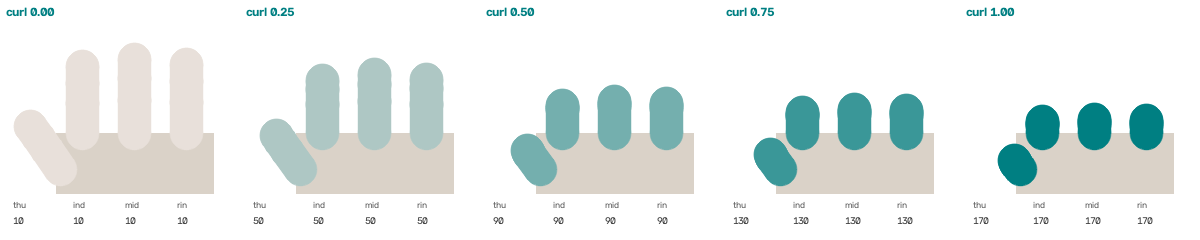

In [ ]:
EVID = "slide_evidence"
os.makedirs(EVID, exist_ok=True)
RESULTS = {}          # every number for the slide is stored here and printed in part 10

def save_img(name, bgr):
    cv2.imwrite(f"{EVID}/{name}", bgr)
    print("Saved:", f"{EVID}/{name}")


def draw_virtual_hand(curls, size=360, title=None):
    """Front view of the robot hand. curls: {finger: 0..1}. Returns a BGR image (size x size)."""
    s = size / 360.0
    img = np.full((size, size, 3), 255, np.uint8)
    has_thumb = "thumb" in ACTIVE_FINGERS
    others = [f for f in ACTIVE_FINGERS if f != "thumb"]
    palm_l, palm_r = int((85 if has_thumb else 40) * s), int(320 * s)
    palm_top, palm_bot = int(200 * s), int(290 * s)
    cv2.rectangle(img, (palm_l, palm_top), (palm_r, palm_bot), (200, 210, 218), -1)
    lengths = {"thumb": 75, "index": 100, "middle": 110, "ring": 102, "pinky": 82}
    seg_frac, bends = (0.45, 0.30, 0.25), (75, 95, 65)          # one tendon bends the 3 joints together
    servo = curls_to_servo({f: curls.get(f, 0.0) for f in ACTIVE_FINGERS})
    slot = (palm_r - palm_l) / max(len(others), 1)
    fw = max(int(slot * 0.62), 4)

    def draw_finger(f, x, y, ang):
        c = float(np.clip(curls.get(f, 0.0), 0.0, 1.0))
        col = tuple(int(a + (b - a) * c) for a, b in zip((218, 224, 232), (130, 127, 0)))   # skin -> teal (BGR)
        sa, ca, cum = np.sin(np.radians(ang)), np.cos(np.radians(ang)), 0.0
        for k in range(3):
            cum += bends[k] * c
            proj = lengths[f] * s * seg_frac[k] * max(np.cos(np.radians(cum)), 0.10)
            x2, y2 = int(x + proj * sa), int(y - proj * ca)
            cv2.line(img, (int(x), int(y)), (x2, y2), col, fw, cv2.LINE_AA)
            cv2.circle(img, (x2, y2), fw // 2, col, -1, cv2.LINE_AA)
            x, y = x2, y2

    label_x = {}
    for i, f in enumerate(others):
        x = int(palm_l + slot * (i + 0.5)); draw_finger(f, x, palm_top, 0); label_x[f] = x
    if has_thumb:
        draw_finger("thumb", int(palm_l + 6 * s), int(palm_top + 55 * s), -35); label_x["thumb"] = int(34 * s)
    for f in ACTIVE_FINGERS:
        x = label_x[f]
        cv2.putText(img, f[:3], (x - int(14 * s), int(312 * s)), cv2.FONT_HERSHEY_SIMPLEX, 0.45 * s, (90, 90, 90), 1, cv2.LINE_AA)
        cv2.putText(img, str(servo[f]), (x - int(14 * s), int(336 * s)), cv2.FONT_HERSHEY_SIMPLEX, 0.5 * s, (60, 60, 60), 1, cv2.LINE_AA)
    if title:
        cv2.putText(img, title, (int(10 * s), int(24 * s)), cv2.FONT_HERSHEY_SIMPLEX, 0.6 * s, (130, 127, 0), 2, cv2.LINE_AA)
    return img

strip = [draw_virtual_hand({f: v for f in ACTIVE_FINGERS}, 240, f"curl {v:.2f}") for v in (0.0, 0.25, 0.5, 0.75, 1.0)]
cv2_imshow(np.hstack(strip))

## 2. Quick check: hand tracking on one photo

Click **Capture** with your hand in view (good light, plain background, whole hand visible).

<IPython.core.display.Javascript object>

Hand found. Label: Left | score: 0.93
Curls : {'thumb': 0.07, 'index': 0.04, 'middle': 0.1, 'ring': 0.02}
Serial: F,21,16,26,14


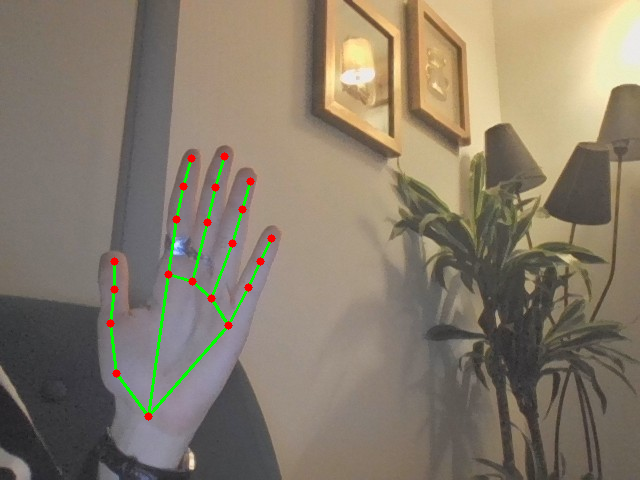

Saved: slide_evidence/01_hand_skeleton.jpg


In [ ]:
photo_path = take_photo("photo.jpg")
img = cv2.imread(photo_path)
res = detect_bgr(make_detector("IMAGE"), img)
RESULTS["photo_hand_found"] = bool(res.hand_landmarks)
if res.hand_landmarks:
    print("Hand found. Label:", res.handedness[0][0].category_name, "| score:", round(res.handedness[0][0].score, 2))
    curls = finger_curls(res.hand_world_landmarks[0])
    print("Curls :", {k: round(v, 2) for k, v in curls.items()})
    print("Serial:", serial_line(curls_to_servo(curls)))
    out = draw_hands(img.copy(), res)
    cv2_imshow(out); save_img("01_hand_skeleton.jpg", out)
else:
    print("No hand detected. Try better light, a plain background, and keep the full hand in view.")

## 3. Calibration of a person (human side)

**What it is:** it tells the system what "fully open" and "fist" look like in degrees **for the person in front of the camera**. It is separate from the robot's servo range (`SERVO_RANGE`, set once on the real hand).

**Why it does not tie the robot to one hand:** hand size does not matter (curls come from joint angles). Calibration only compensates for different ranges of motion. The defaults work as a fallback for anyone, calibration is an optional 6-second step that improves the result, and the **automatic mode** (part 5) needs no step at all. Each person keeps their own profile in `calibration_profiles.json`.

**Do this:** set `PERSON` in part 1, run the cell, **keep the hand fully open for 3 seconds, then close it into a fist for 3 seconds**.

In [ ]:
def extract(path):
    """Run MediaPipe on a video. Returns (table of flexion per frame, list of results, inference times in ms, fps)."""
    detector = make_detector("VIDEO")
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    rows, results, times, idx = [], [], [], 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        ts = int(idx * 1000 / fps)
        t0 = time.perf_counter()
        res = detect_bgr(detector, frame, ts)
        times.append((time.perf_counter() - t0) * 1000)
        results.append(res)
        found = bool(res.hand_world_landmarks)
        flex = finger_flexion(res.hand_world_landmarks[0]) if found else {f: np.nan for f in ACTIVE_FINGERS}
        row = {"frame": idx, "t_ms": ts, "hand_detected": int(found)}
        row.update({f"flex_{f}": v for f, v in flex.items()})
        rows.append(row); idx += 1
    cap.release()
    return pd.DataFrame(rows), results, np.array(times), fps


def curl_table(df, mode="profile"):
    """Flexion table -> smoothed curls and servo angles.
    mode: 'default' (fallback values), 'profile' (the active CALIB) or 'auto' (automatic calibration)."""
    filters = {f: OneEuro(min_cutoff=1.0, beta=0.05) for f in ACTIVE_FINGERS}
    auto = AdaptiveCalib() if mode == "auto" else None
    calib = CALIB_DEFAULT if mode == "default" else CALIB
    last = {f: 0.0 for f in ACTIVE_FINGERS}
    rows = []
    for r in df.itertuples(index=False):
        raw = {f: np.nan for f in ACTIVE_FINGERS}
        if r.hand_detected:
            flex = {f: getattr(r, f"flex_{f}") for f in ACTIVE_FINGERS}
            raw = curls_from_flex(flex, auto.update(flex) if auto else calib)
            last = {f: float(filters[f](v, r.t_ms / 1000.0)) for f, v in raw.items()}
        row = {"frame": r.frame, "t_ms": r.t_ms, "hand_detected": r.hand_detected}
        row.update({f"curl_raw_{f}": raw[f] for f in ACTIVE_FINGERS})
        row.update({f"curl_{f}": last[f] for f in ACTIVE_FINGERS})
        row.update({f"servo_{f}": v for f, v in curls_to_servo(last).items()})
        rows.append(row)
    return pd.DataFrame(rows)


def calibrate_person(name):
    print("Keep the hand OPEN for 3 s, then make a FIST for 3 s.")
    mp4 = to_mp4(record_video("calib.webm", seconds=6), "calib.mp4")
    df, _, _, _ = extract(mp4)
    det = df[df.hand_detected == 1]
    if len(det) < 30:
        print("Not enough frames with a detected hand. Keep the hand in view and retry.")
        return
    for f in ACTIVE_FINGERS:
        lo, hi = float(np.percentile(det[f"flex_{f}"], 5)), float(np.percentile(det[f"flex_{f}"], 95))
        if hi - lo < 30:
            print(f"WARNING {f}: small range ({lo:.0f} to {hi:.0f} deg), default kept. Did you really open and close the hand?")
        else:
            CALIB[f] = {"open": lo, "closed": hi}
        print(f"{f:7s}: open = {CALIB[f]['open']:5.1f} deg | closed = {CALIB[f]['closed']:5.1f} deg")
    save_profile(name)
    RESULTS["calibrated_person"] = name

calibrate_person(PERSON)

Keep the hand OPEN for 3 s, then make a FIST for 3 s.


<IPython.core.display.Javascript object>

Recording 6 s... move your hand and open/close your fingers.
thumb  : open =   6.5 deg | closed =  48.5 deg
index  : open =  14.5 deg | closed =  80.7 deg
middle : open =  23.5 deg | closed =  84.5 deg
ring   : open =  19.9 deg | closed =  88.9 deg
Profile 'person1' saved in calibration_profiles.json


## 4. Tracking and teleoperation demo (virtual hand)

Record 5 seconds: **open and close your hand slowly 2 or 3 times**. You get the hand detection rate, the tracking speed, a side-by-side video (your tracked hand on the left, the **virtual robot hand** on the right), and the finger-curl plot.

<IPython.core.display.Javascript object>

Recording 5 s... move your hand and open/close your fingers.
Frames: 149 | hand detected in 100% of them (target: 90% or more)
MediaPipe: 12.5 ms/frame mean, 14.3 ms p95 (about 80 FPS max on this machine; Colab CPU is only indicative)
Saved: slide_evidence/02_mirror_open.jpg
Saved: slide_evidence/02_mirror_closed.jpg


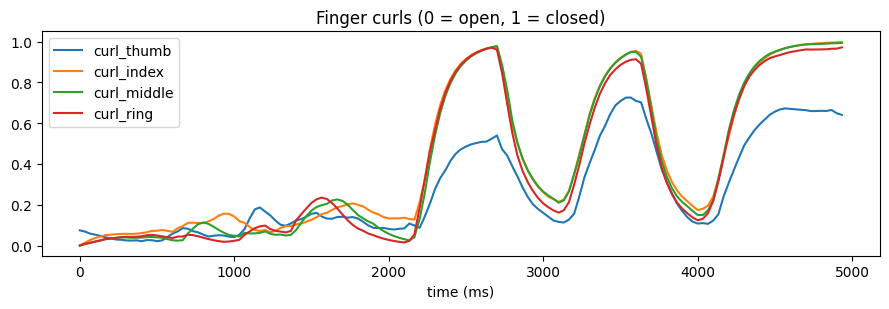

In [ ]:
def render_mirror(path, ctab, results, fps, out_final="slide_evidence/02_mirror_clip.mp4"):
    cap = cv2.VideoCapture(path)
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    curl_cols = [f"curl_{f}" for f in ACTIVE_FINGERS]
    avg = ctab[curl_cols].mean(axis=1).values
    det = ctab.hand_detected.values.astype(bool)
    i_open = int(np.argmin(np.where(det, avg, 9))) if det.any() else 0
    i_closed = int(np.argmax(np.where(det, avg, -9))) if det.any() else 0
    writer = cv2.VideoWriter("mirror_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w + h, h))
    idx = 0
    while True:
        ok, frame = cap.read()
        if not ok or idx >= len(results):
            break
        curls = {f: float(ctab.iloc[idx][f"curl_{f}"]) for f in ACTIVE_FINGERS}
        comp = np.hstack([draw_hands(frame.copy(), results[idx]), draw_virtual_hand(curls, h, "virtual robot hand")])
        writer.write(comp)
        if idx == i_open: save_img("02_mirror_open.jpg", comp)
        if idx == i_closed: save_img("02_mirror_closed.jpg", comp)
        idx += 1
    cap.release(); writer.release()
    to_mp4("mirror_raw.mp4", out_final, fps=int(round(fps)))
    show_video(out_final, width=900)


def run_tracking_test(seconds=5):
    mp4 = to_mp4(record_video("clip.webm", seconds=seconds), "clip.mp4")
    df, results, times, fps = extract(mp4)
    rate = float(df.hand_detected.mean())
    RESULTS.update(clip_detect_rate=rate, clip_frames=len(df), track_ms_mean=float(times.mean()),
                   track_ms_p95=float(np.percentile(times, 95)))
    print(f"Frames: {len(df)} | hand detected in {rate*100:.0f}% of them (target: 90% or more)")
    print(f"MediaPipe: {times.mean():.1f} ms/frame mean, {np.percentile(times, 95):.1f} ms p95 "
          f"(about {1000/times.mean():.0f} FPS max on this machine; Colab CPU is only indicative)")
    if rate < 0.9:
        print("Tip: better light, plain background, whole hand in view, camera at 40 to 60 cm.")
    ctab = curl_table(df, "profile")
    render_mirror(mp4, ctab, results, fps)
    ctab.plot(x="t_ms", y=[f"curl_{f}" for f in ACTIVE_FINGERS], figsize=(9, 3.2), ylim=(-0.05, 1.05),
              title="Finger curls (0 = open, 1 = closed)")
    plt.xlabel("time (ms)"); plt.tight_layout(); plt.savefig(f"{EVID}/03_finger_curls.png", dpi=150); plt.show()
    ctab.merge(df[["frame"] + [f"flex_{f}" for f in ACTIVE_FINGERS]], on="frame").to_csv("landmarks_curls.csv", index=False)
    return df

df_clip = run_tracking_test()

## 5. Does calibration help? Default vs. calibrated vs. automatic

The same recorded clip is converted to curls three ways. The measure is the **range of curl actually used** (95th minus 5th percentile): a perfect calibration uses most of the 0 to 1 range, so the robot finger opens and closes fully. A small range means the robot hand would not follow the person's full movement.

**Team test:** each member sets `PERSON`, runs part 3 (calibration) then part 4 (clip), then this cell. The results of all persons are appended to `07_calibration_comparison.csv`, which gives you the "mimics any hand" evidence for the report.

,person,mode,span_thumb,span_index,span_middle,span_ring,span_mean
0,person1,default,0.41,0.72,0.67,0.73,0.63
1,person1,profile,0.64,0.93,0.96,0.94,0.87
2,person1,auto,0.41,0.81,0.75,0.83,0.70


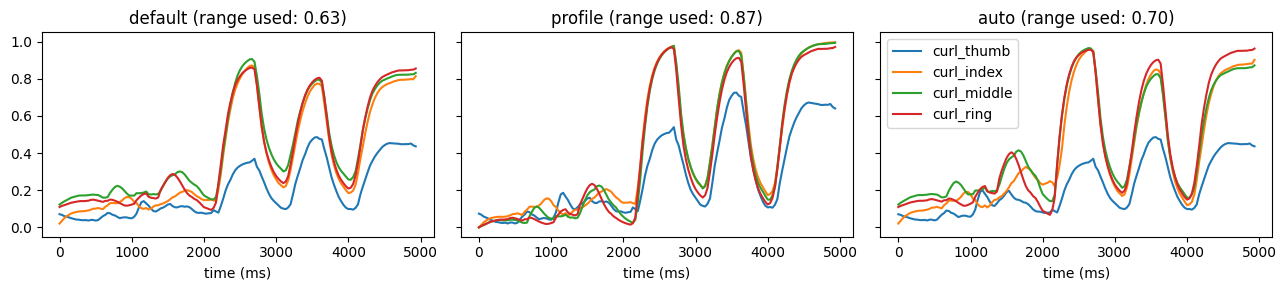

In [ ]:
def compare_calibrations(df_flex, person):
    modes = ["default", "profile", "auto"]
    tabs = {m: curl_table(df_flex, m) for m in modes}
    rows = []
    for m in modes:
        t = tabs[m][tabs[m].hand_detected == 1]
        spans = {f: float(np.percentile(t[f"curl_{f}"], 95) - np.percentile(t[f"curl_{f}"], 5)) for f in ACTIVE_FINGERS}
        row = {"person": person, "mode": m}
        row.update({f"span_{f}": round(v, 2) for f, v in spans.items()})
        row["span_mean"] = round(float(np.mean(list(spans.values()))), 2)
        rows.append(row)
    res = pd.DataFrame(rows)
    path = f"{EVID}/07_calibration_comparison.csv"
    res.to_csv(path, mode="a", header=not os.path.exists(path), index=False)
    display(res)
    RESULTS["calib_span"] = {r["mode"]: r["span_mean"] for r in rows}
    fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
    for ax, m in zip(axes, modes):
        tabs[m].plot(x="t_ms", y=[f"curl_{f}" for f in ACTIVE_FINGERS], ax=ax, legend=(m == "auto"), ylim=(-0.05, 1.05))
        ax.set_title(f"{m} (range used: {res.loc[res['mode'] == m, 'span_mean'].values[0]:.2f})"); ax.set_xlabel("time (ms)")
    plt.tight_layout(); plt.savefig(f"{EVID}/07_calibration_comparison.png", dpi=150); plt.show()

compare_calibrations(df_clip, PERSON)

## 6. Object detection (YOLO)

A small pretrained **YOLO** model (COCO dataset, 80 everyday classes) detects objects with no training. Pick your 4 to 6 project objects among COCO classes and edit `OBJECT_SET`.

In [ ]:
from ultralytics import YOLO

try:
    yolo = YOLO("yolo11n.pt")
except Exception:
    yolo = YOLO("yolov8n.pt")
print("Model loaded. Classes:", len(yolo.names))

# ======== EDIT: the objects of your project (must be COCO class names) ========
OBJECT_SET = ["sports ball", "cup", "bottle", "apple", "banana", "remote"]
# ===============================================================================
missing = [o for o in OBJECT_SET if o not in yolo.names.values()]
print("Not a COCO class (pick another name):", missing) if missing else print("All objects are known classes.")

DET_CONF = 0.25     # detection threshold used in the pipeline demo (0.35 = stricter, 0.15 = finds more but more false alarms)

def run_yolo(bgr, conf=None):
    r = yolo.predict(bgr, conf=DET_CONF if conf is None else conf, verbose=False)[0]
    return [{"label": r.names[int(b.cls[0])], "conf": float(b.conf[0]),
             "xyxy": [float(v) for v in b.xyxy[0]]} for b in r.boxes]

def draw_detections(bgr, dets, target=None):
    out = bgr.copy()
    for d in dets:
        x1, y1, x2, y2 = map(int, d["xyxy"])
        color = (130, 127, 0) if d["label"] in OBJECT_SET else (160, 160, 160)     # teal = one of our objects
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 4 if (target is not None and d is target) else 2)
        cv2.putText(out, f'{d["label"]} {d["conf"]:.2f}', (x1, max(y1 - 6, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2, cv2.LINE_AA)
    return out

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model loaded. Classes: 80
All objects are known classes.


**6a. Test on photos of your objects** (one photo per object, taken with a phone or the webcam, object alone on a plain table, side view, close up).
Name each file after its object (`apple.jpg`, `cup.jpg`, `bottle.jpg`, `banane.jpg`, `sport_ball.jpg`, `remote.jpg`...) so the notebook knows what to expect. Each photo is tested at two thresholds (0.35 and 0.15). Edit `EXPECTED` if your file names differ.

Saving sport_ball.jpg to sport_ball.jpg
Saving remote.jpg to remote.jpg
Saving cup.jpg to cup.jpg
Saving bottle.jpg to bottle.jpg
Saving banane.jpg to banane.jpg
Saving apple.jpg to apple.jpg


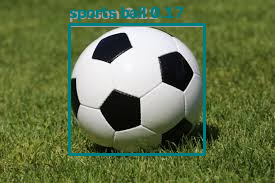

Saved: slide_evidence/04_yolo_sport_ball.jpg


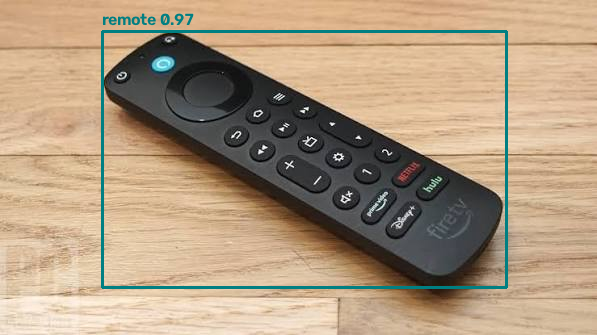

Saved: slide_evidence/04_yolo_remote.jpg


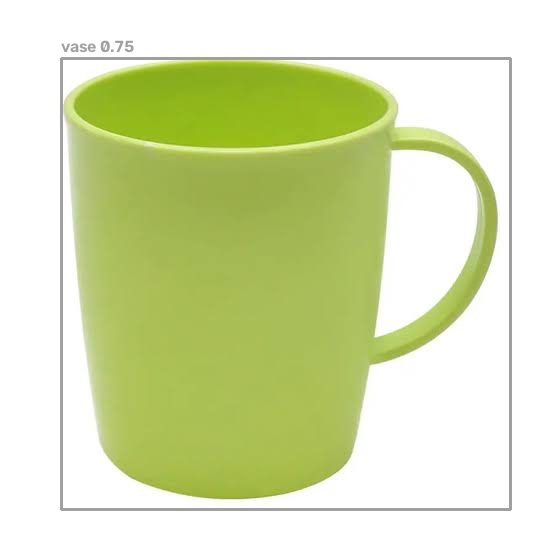

Saved: slide_evidence/04_yolo_cup.jpg


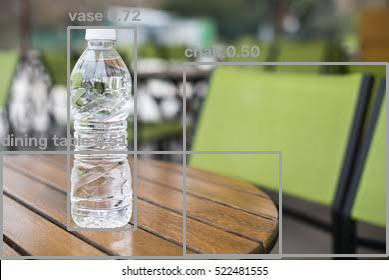

Saved: slide_evidence/04_yolo_bottle.jpg


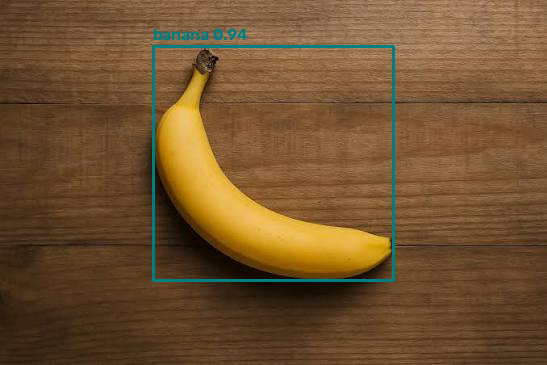

Saved: slide_evidence/04_yolo_banane.jpg


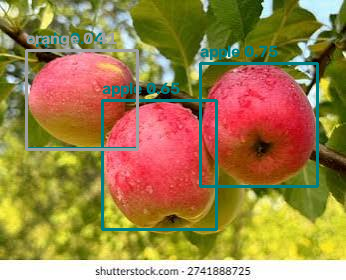

Saved: slide_evidence/04_yolo_apple.jpg


,image,expected,detected@0.35,found@0.35,detected@0.15,found@0.15
0,sport_ball.jpg,sports ball,nothing,no,"person 0.21, sports ball 0.17",yes
1,remote.jpg,remote,remote 0.97,yes,remote 0.97,yes
2,cup.jpg,cup,vase 0.75,no,vase 0.75,no
3,bottle.jpg,bottle,"vase 0.72, dining table 0.51, chair 0.50",no,"vase 0.72, dining table 0.51, chair 0.50, chai...",no
4,banane.jpg,banana,banana 0.94,yes,"banana 0.94, dining table 0.25",yes
5,apple.jpg,apple,"apple 0.75, apple 0.74, apple 0.65, orange 0.41",yes,"apple 0.75, apple 0.74, apple 0.65, orange 0.4...",yes


Objects found: 3 of 6 at 0.35, 4 of 6 at 0.15
Not found at 0.35: ['sports ball', 'cup', 'bottle']


In [ ]:
EXPECTED = {"sport_ball": "sports ball", "ball": "sports ball", "remote": "remote", "cup": "cup", "mug": "cup",
            "bottle": "bottle", "banane": "banana", "banana": "banana", "apple": "apple", "pomme": "apple"}

def expected_label(filename):
    stem = os.path.splitext(os.path.basename(filename))[0].lower()
    return next((lab for key, lab in EXPECTED.items() if key in stem), None)

UPLOADED_IMAGES = []
up = files.upload()
rows = []
for name in up:
    UPLOADED_IMAGES.append(name)
    exp, im = expected_label(name), cv2.imread(name)
    row = {"image": name, "expected": exp or "?"}
    best = None
    for thr in (0.35, 0.15):
        dets = run_yolo(im, conf=thr)
        found = exp is not None and any(d["label"] == exp for d in dets)
        row[f"detected@{thr}"] = ", ".join(f'{d["label"]} {d["conf"]:.2f}' for d in dets) or "nothing"
        row[f"found@{thr}"] = "yes" if found else "no"
        if best is None and found: best = (thr, dets)
    thr, dets = best or (0.35, run_yolo(im, conf=0.35))
    vis = draw_detections(im, dets)
    cv2_imshow(vis); save_img(f"04_yolo_{os.path.splitext(name)[0]}.jpg", vis)
    rows.append(row)

tab = pd.DataFrame(rows)
display(tab)
tab.to_csv(f"{EVID}/04_yolo_results.csv", index=False)
known = tab[tab.expected != "?"]
RESULTS.update(yolo_total=len(known),
               yolo_found_035=int((known["found@0.35"] == "yes").sum()),
               yolo_found_015=int((known["found@0.15"] == "yes").sum()),
               yolo_missed=[row["expected"] for row in rows if row["expected"] != "?" and row["found@0.35"] == "no"])
print(f"Objects found: {RESULTS['yolo_found_035']} of {RESULTS['yolo_total']} at 0.35, "
      f"{RESULTS['yolo_found_015']} of {RESULTS['yolo_total']} at 0.15")
print("Not found at 0.35:", RESULTS["yolo_missed"] or "none")

**6b. Speed, and optional webcam test.** The first cell measures YOLO's time per image (Colab CPU is only indicative, measure again on your laptop). The second takes a webcam photo of your objects on the table.

In [ ]:
bench = cv2.imread(UPLOADED_IMAGES[0]) if UPLOADED_IMAGES else np.zeros((480, 640, 3), np.uint8)
for _ in range(2): run_yolo(bench)                      # warm-up
t0 = time.perf_counter()
for _ in range(10): run_yolo(bench)
RESULTS["yolo_ms"] = (time.perf_counter() - t0) / 10 * 1000
print(f"YOLO inference: {RESULTS['yolo_ms']:.0f} ms per image")

YOLO inference: 87 ms per image


<IPython.core.display.Javascript object>

Detections: [('potted plant', 0.82), ('apple', 0.76), ('couch', 0.35), ('couch', 0.33), ('vase', 0.3)]


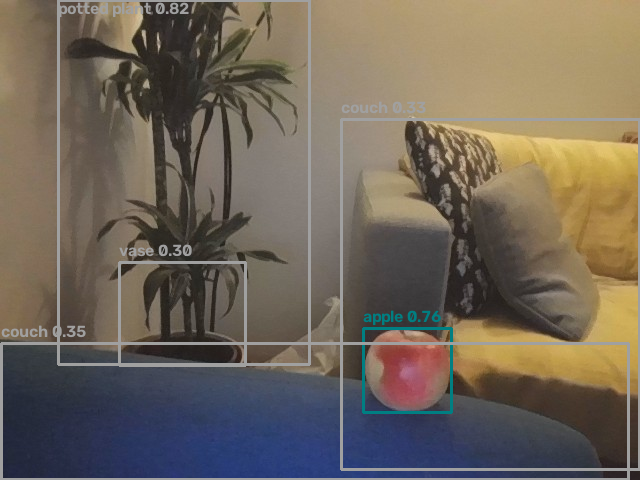

Saved: slide_evidence/04_yolo_webcam.jpg


In [ ]:
photo = cv2.imread(take_photo("objects.jpg"))
dets = run_yolo(photo)
print("Detections:", [(d["label"], round(d["conf"], 2)) for d in dets] or "none (better light, move closer)")
vis = draw_detections(photo, dets)
cv2_imshow(vis); save_img("04_yolo_webcam.jpg", vis)

## 7. Rule-based grasp baseline (Baseline 1)

`object class -> grasp preset (one curl per finger) -> servo angles -> serial message`. A grasp has three steps: *open*, *pre-shape* (partly closed while approaching), *close*. The values are starting guesses, **to be tuned on the real hand** by closing each finger until the object is held without crushing it. Presets are stored **per finger name**, so they follow `ACTIVE_FINGERS`.

,object,grasp,curls (close),serial (close)
0,sports ball,spherical power grasp,"[0.55, 0.6, 0.6, 0.55]","F,98,106,106,98"
1,cup,cylindrical grasp,"[0.5, 0.55, 0.55, 0.5]","F,90,98,98,90"
2,bottle,cylindrical grasp,"[0.45, 0.5, 0.5, 0.45]","F,82,90,90,82"
3,apple,spherical power grasp,"[0.55, 0.6, 0.6, 0.55]","F,98,106,106,98"
4,banana,thin cylindrical grasp,"[0.65, 0.7, 0.7, 0.65]","F,114,122,122,114"
5,remote,flat object hold,"[0.6, 0.65, 0.65, 0.55]","F,106,114,114,98"


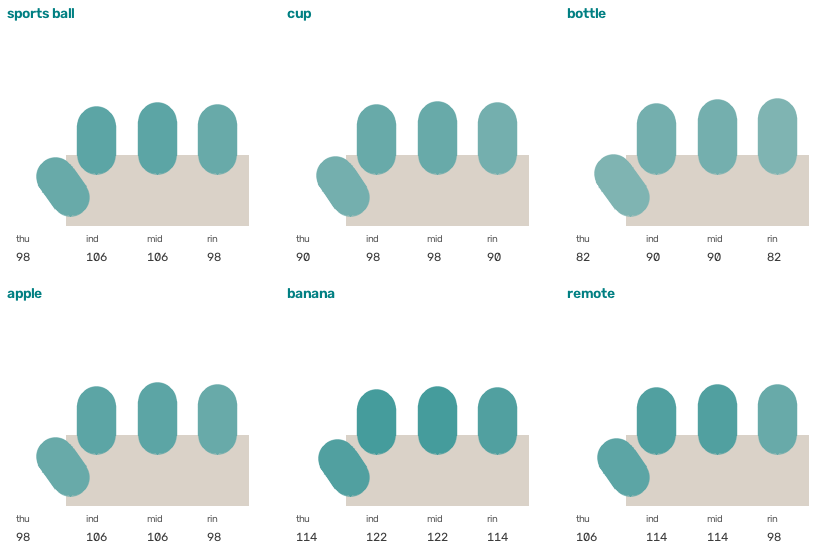

Saved: slide_evidence/05_grasp_presets_gallery.png


In [ ]:
GRASP_PRESETS = {   # object: (grasp type, {finger: curl})
    "sports ball": ("spherical power grasp",  {"thumb": 0.55, "index": 0.60, "middle": 0.60, "ring": 0.55, "pinky": 0.50}),
    "apple":       ("spherical power grasp",  {"thumb": 0.55, "index": 0.60, "middle": 0.60, "ring": 0.55, "pinky": 0.50}),
    "orange":      ("spherical power grasp",  {"thumb": 0.55, "index": 0.60, "middle": 0.60, "ring": 0.55, "pinky": 0.50}),
    "cup":         ("cylindrical grasp",      {"thumb": 0.50, "index": 0.55, "middle": 0.55, "ring": 0.50, "pinky": 0.45}),
    "bottle":      ("cylindrical grasp",      {"thumb": 0.45, "index": 0.50, "middle": 0.50, "ring": 0.45, "pinky": 0.40}),
    "banana":      ("thin cylindrical grasp", {"thumb": 0.65, "index": 0.70, "middle": 0.70, "ring": 0.65, "pinky": 0.60}),
    "remote":      ("flat object hold",       {"thumb": 0.60, "index": 0.65, "middle": 0.65, "ring": 0.55, "pinky": 0.50}),
    "cell phone":  ("flat object hold",       {"thumb": 0.60, "index": 0.65, "middle": 0.65, "ring": 0.55, "pinky": 0.50}),
    "book":        ("flat object hold",       {"thumb": 0.40, "index": 0.45, "middle": 0.45, "ring": 0.40, "pinky": 0.35}),
}
PRESHAPE = 0.4     # fraction of the final closure used while approaching the object

def preset_curls(label):
    name, vals = GRASP_PRESETS[label]
    fallback = float(np.mean(list(vals.values())))
    return name, {f: vals.get(f, fallback) for f in ACTIVE_FINGERS}

def choose_target(dets):
    """Most confident detection among the project objects (None if there is none)."""
    cands = [d for d in dets if d["label"] in OBJECT_SET and d["label"] in GRASP_PRESETS]
    return max(cands, key=lambda d: d["conf"]) if cands else None

def grasp_sequence(label):
    """[(step, curls, servo angles, serial message)] for open, pre-shape, close."""
    name, close = preset_curls(label)
    steps = [("open", {f: 0.0 for f in ACTIVE_FINGERS}),
             ("pre-shape", {f: c * PRESHAPE for f, c in close.items()}),
             ("close", close)]
    return name, [(s, c, curls_to_servo(c), serial_line(curls_to_servo(c))) for s, c in steps]

# Table of the baseline + gallery (for the slide)
rows, tiles = [], []
for label in OBJECT_SET:
    if label not in GRASP_PRESETS:
        print("No preset for", label, "- add one in GRASP_PRESETS"); continue
    gname, seq = grasp_sequence(label)
    rows.append({"object": label, "grasp": gname, "curls (close)": [round(v, 2) for v in seq[-1][1].values()],
                 "serial (close)": seq[-1][3]})
    tiles.append(draw_virtual_hand(seq[-1][1], 280, label))
table = pd.DataFrame(rows); display(table)
table.to_csv(f"{EVID}/05_grasp_presets.csv", index=False)
RESULTS["n_presets"] = len(rows)
blank = np.full_like(tiles[0], 255)
grid = np.vstack([np.hstack((tiles[i:i + 3] + [blank] * 3)[:3]) for i in range(0, len(tiles), 3)])
cv2_imshow(grid); save_img("05_grasp_presets_gallery.png", grid)

## 8. Full pipeline demo

Image, object detection, grasp choice, virtual hand closing on the object, and the 3 serial messages that would go to the ESP32. The first cell runs it on the photos uploaded in part 6; the second on a new webcam photo.

[sport_ball] No project object detected. Detections: none
[remote] Target: remote (0.97) -> flat object hold
    open       F,10,10,10,10
    pre-shape  F,48,52,52,45
    close      F,106,114,114,98


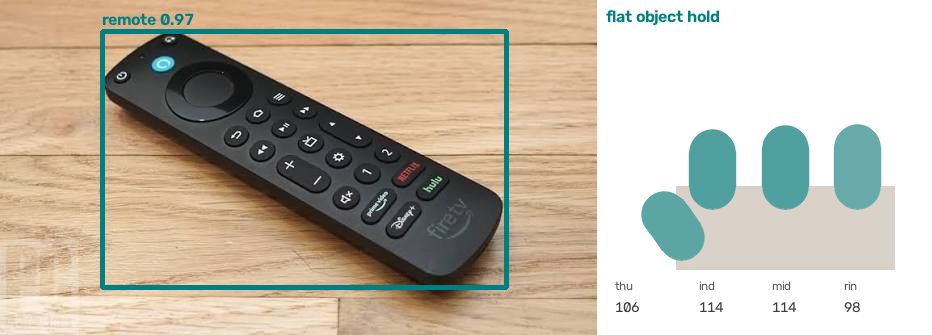

Saved: slide_evidence/06_pipeline_remote.jpg


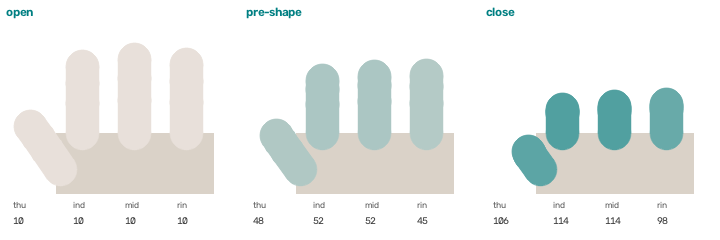

[cup] No project object detected. Detections: [('vase', 0.75)]
[bottle] No project object detected. Detections: [('vase', 0.72), ('dining table', 0.51), ('chair', 0.5)]
[banane] Target: banana (0.94) -> thin cylindrical grasp
    open       F,10,10,10,10
    pre-shape  F,52,55,55,52
    close      F,114,122,122,114


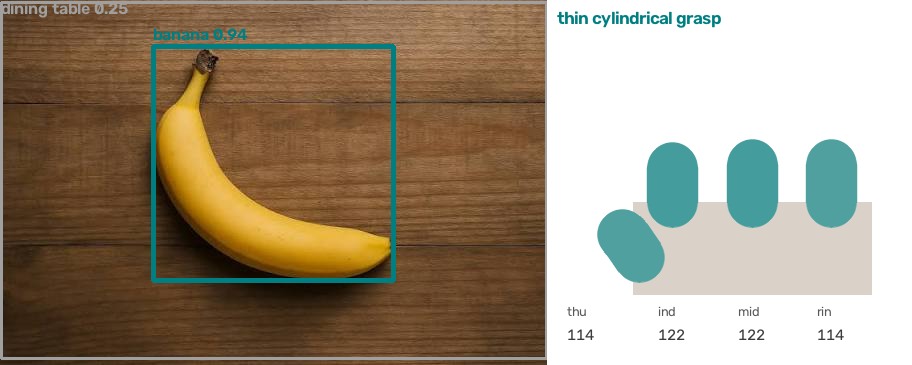

Saved: slide_evidence/06_pipeline_banane.jpg


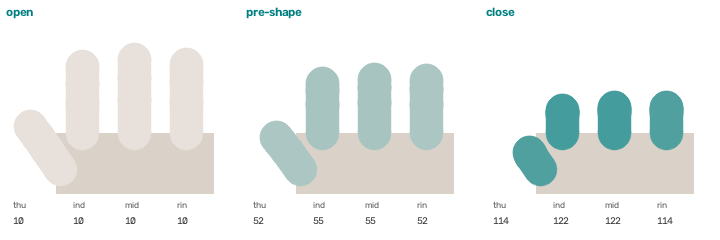

[apple] Target: apple (0.75) -> spherical power grasp
    open       F,10,10,10,10
    pre-shape  F,45,48,48,45
    close      F,98,106,106,98


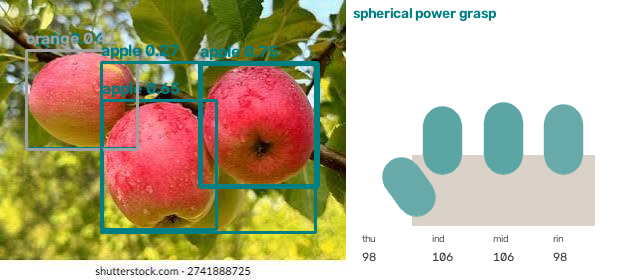

Saved: slide_evidence/06_pipeline_apple.jpg


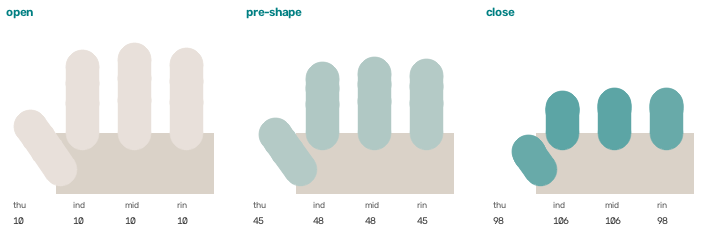

Pipeline worked on 3 of 6 photos


In [ ]:
def pipeline_demo(bgr, name="demo"):
    dets = run_yolo(bgr)
    target = choose_target(dets)
    vis = draw_detections(bgr, dets, target)
    h = vis.shape[0]
    if target is None:
        print(f"[{name}] No project object detected. Detections:", [(d["label"], round(d["conf"], 2)) for d in dets] or "none")
        return False
    gname, seq = grasp_sequence(target["label"])
    print(f'[{name}] Target: {target["label"]} ({target["conf"]:.2f}) -> {gname}')
    for step, curls, servo, msg in seq:
        print(f"    {step:10s} {msg}")
    comp = np.hstack([vis, draw_virtual_hand(seq[-1][1], h, gname)])
    cv2_imshow(comp); save_img(f"06_pipeline_{name}.jpg", comp)
    cv2_imshow(np.hstack([draw_virtual_hand(c, 240, st) for st, c, _, _ in seq]))
    return True

ok = [pipeline_demo(cv2.imread(p), os.path.splitext(p)[0]) for p in UPLOADED_IMAGES]
RESULTS["pipeline_ok"], RESULTS["pipeline_total"] = int(sum(ok)), len(ok)
print(f"Pipeline worked on {sum(ok)} of {len(ok)} photos")

<IPython.core.display.Javascript object>

[webcam] Target: apple (0.39) -> spherical power grasp
    open       F,10,10,10,10
    pre-shape  F,45,48,48,45
    close      F,98,106,106,98


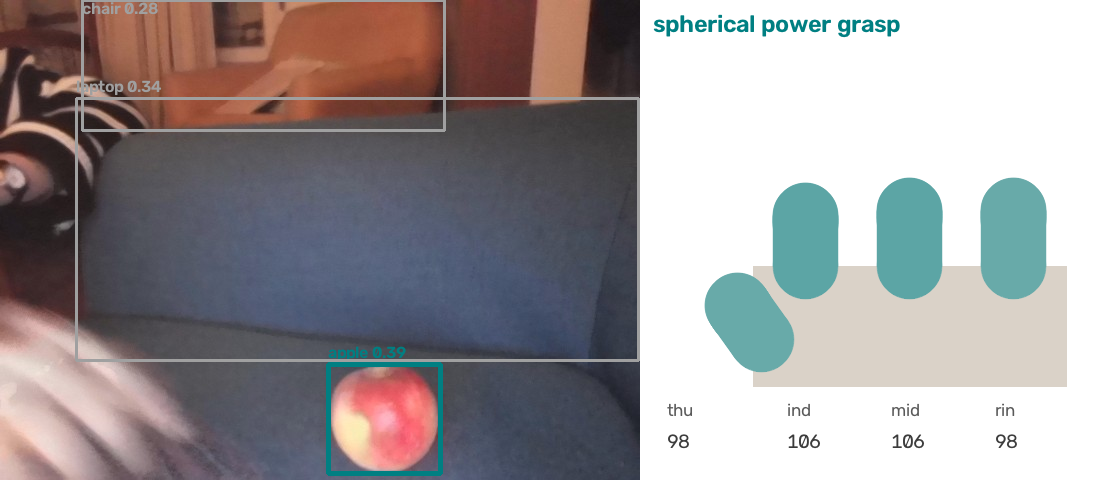

Saved: slide_evidence/06_pipeline_webcam.jpg


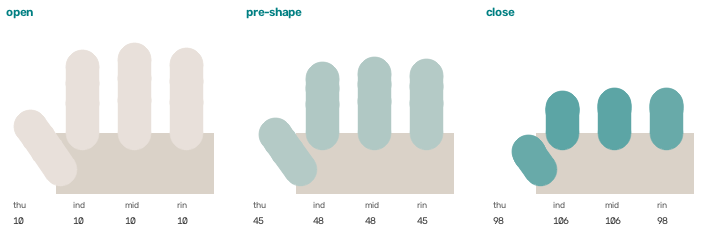

True

In [ ]:
pipeline_demo(cv2.imread(take_photo("pipeline.jpg")), "webcam")

## 9. Dataset

Two kinds of data, in `dataset/`:
- **Object images** (`dataset/images/<object>/`) to check or fine-tune the detector: a short recording per object, moved and rotated.
- **Teleoperation episodes** (`dataset/episodes/`): video + CSV with flexion, raw and smoothed curls, and servo angles per frame, with the person and calibration mode. Later the same format will hold the real servo commands.

`dataset/manifest.csv` lists everything. **Do not interrupt a recording cell**: it waits for the recording length (a few seconds) and the browser permission.

In [ ]:
DATA_DIR = "dataset"
for sub in ("images", "episodes"):
    os.makedirs(f"{DATA_DIR}/{sub}", exist_ok=True)
MANIFEST = f"{DATA_DIR}/manifest.csv"
EPISODE_CALIB_MODE = "profile"      # 'profile' (your calibration), 'auto' or 'default'


def collect_object_images(label, seconds=10, fps=5):
    """Record the object (move and rotate it), then save about seconds*fps images."""
    key = label.replace(" ", "_")
    out_dir = f"{DATA_DIR}/images/{key}"
    os.makedirs(out_dir, exist_ok=True)
    start = len(glob.glob(out_dir + "/*.jpg"))
    webm = record_video("tmp_objects.webm", seconds=seconds)
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", webm, "-vf", f"fps={fps}", "-q:v", "2",
                    "-start_number", str(start), f"{out_dir}/{key}_%04d.jpg"], check=True)
    n = len(glob.glob(out_dir + "/*.jpg"))
    print(f"{label}: {n - start} new images, {n} in total")
    imgs = sorted(glob.glob(out_dir + "/*.jpg"))[-8:]
    cv2_imshow(np.hstack([cv2.resize(cv2.imread(p), (200, 150)) for p in imgs]))


def record_episode(task, seconds=5, quiet=False):
    """Record a clip, track the hand, save video + CSV + manifest row."""
    ep_id = f"ep_{len(glob.glob(DATA_DIR + '/episodes/*.csv')):04d}"
    mp4 = to_mp4(record_video("tmp_episode.webm", seconds=seconds), f"{DATA_DIR}/episodes/{ep_id}.mp4")
    df, _, _, fps = extract(mp4)
    ctab = curl_table(df, EPISODE_CALIB_MODE)
    full = ctab.merge(df[["frame"] + [f"flex_{f}" for f in ACTIVE_FINGERS]], on="frame")
    full.to_csv(f"{DATA_DIR}/episodes/{ep_id}.csv", index=False)
    entry = pd.DataFrame([{"episode": ep_id, "task": task, "person": PERSON, "calib_mode": EPISODE_CALIB_MODE,
                           "frames": len(df), "fps": round(fps, 1), "duration_s": round(len(df) / fps, 1),
                           "detection_rate": round(float(df.hand_detected.mean()), 3)}])
    entry.to_csv(MANIFEST, mode="a", header=not os.path.exists(MANIFEST), index=False)
    if not quiet: print(entry.to_string(index=False))
    if entry.detection_rate.iloc[0] < 0.9:
        print("   Low detection rate: you may want to delete this episode and repeat it (better light, whole hand in view).")
    return full


def record_episodes(task, n=5, seconds=5):
    """Record n episodes one after the other (each one waits for the camera)."""
    for i in range(n):
        print(f"Episode {i + 1}/{n}: open and close the hand slowly, start and end with an open hand.")
        record_episode(task, seconds=seconds)

**9a. Object images.** Change `label`, run again for each object of `OBJECT_SET` (about 50 images per object).

<IPython.core.display.Javascript object>

Recording 10 s... move your hand and open/close your fingers.
sports ball: 50 new images, 100 in total


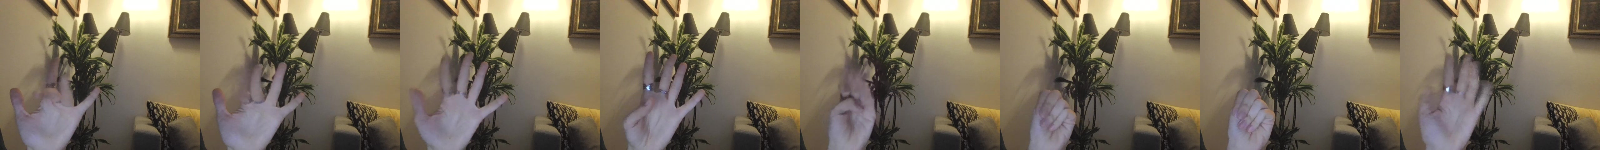

In [ ]:
collect_object_images("sports ball", seconds=10)

**9b. Teleoperation episodes.** Aim for **20 to 30 episodes** (use `record_episodes` to do several in a row), ideally from several team members.

<IPython.core.display.Javascript object>

Recording 5 s... move your hand and open/close your fingers.
episode       task  person calib_mode  frames  fps  duration_s  detection_rate
ep_0000 open_close person1    profile     149 30.0         5.0             1.0


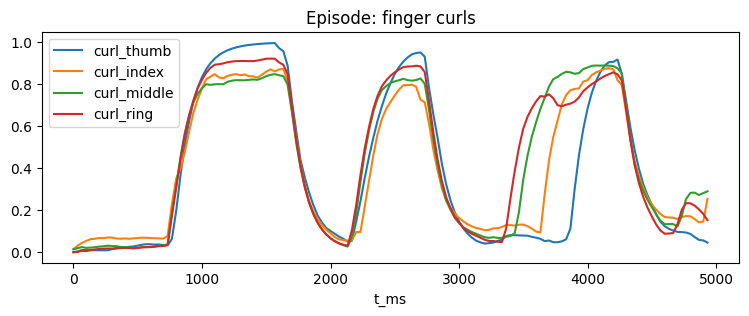

In [ ]:
df_ep = record_episode("open_close", seconds=5)
df_ep.plot(x="t_ms", y=[f"curl_{f}" for f in ACTIVE_FINGERS], figsize=(9, 3), ylim=(-0.05, 1.05), title="Episode: finger curls")
plt.show()

In [ ]:
# record_episodes("open_close", n=5)      # uncomment to record 5 episodes in a row

## 10. Results summary for the slide

Run this cell last. It prints the text and numbers for **slide 5**, estimates the completion percentage (with the breakdown, so you can justify it), saves everything in `slide_evidence/slide_summary.md`, and downloads `slide_evidence.zip` and `dataset.zip`.

In [ ]:
def build_summary(R, n_episodes=0, images=None):
    images = images or {}
    n_img = sum(images.values())
    def has(k): return k in R and R[k] is not None
    rows, parts = [], {}

    # tracking
    if has("clip_detect_rate"):
        dr, ms = R["clip_detect_rate"], R["track_ms_mean"]
        status = "Done" if dr >= 0.9 else "Done, to improve"
        rows.append(("MediaPipe hand tracking", status,
                     f"Hand found in {dr*100:.0f}% of frames, {ms:.1f} ms/frame (up to {1000/ms:.0f} FPS)"))
        parts["Hand tracking (15)"] = 15 * min(dr / 0.9, 1.0)
    else:
        rows.append(("MediaPipe hand tracking", "Not run yet", "Run part 4")); parts["Hand tracking (15)"] = 0

    # curls / calibration
    cs = R.get("calib_span", {})
    who = R.get("calibrated_person")
    txt = "One Euro filter; 4 curls (thumb, index, middle, ring) to 4 servo angles"
    if cs:
        txt += f"; range used: default {cs.get('default', 0):.2f}, calibrated {cs.get('profile', 0):.2f}, automatic {cs.get('auto', 0):.2f}"
    rows.append(("Curls, calibration, servo mapping", "Done" if who or cs else "Defaults only", txt))
    parts["Curls, calibration, servo map (10)"] = 10 if (who and cs) else (6 if cs or who else 3)

    # detection
    if has("yolo_total") and R["yolo_total"]:
        f35, f15, tot = R["yolo_found_035"], R["yolo_found_015"], R["yolo_total"]
        ms = f", {R['yolo_ms']:.0f} ms/image" if has("yolo_ms") else ""
        miss = f". Not found: {', '.join(R['yolo_missed'])}" if R.get("yolo_missed") else ""
        rows.append(("Object detection (YOLO)", "Done" if f35 == tot else "Partial",
                     f"{f35} of {tot} test objects found (threshold 0.35), {f15} of {tot} at 0.15{ms}{miss}"))
        parts["Object detection (15)"] = 15 * max(f35, f15) / tot
    else:
        rows.append(("Object detection (YOLO)", "Not run yet", "Run part 6")); parts["Object detection (15)"] = 0

    # baseline + virtual hand + pipeline
    if has("n_presets"):
        pipe = f"; pipeline demo worked on {R['pipeline_ok']} of {R['pipeline_total']} photos" if has("pipeline_total") and R["pipeline_total"] else ""
        rows.append(("Rule-based grasp and virtual hand", "Done in simulation",
                     f"{R['n_presets']} grasp presets, webcam clip mirrored by the virtual hand{pipe}; not yet tested on the real hand"))
        parts["Grasp baseline and virtual hand (10)"] = 10 if has("clip_detect_rate") else 6
    else:
        rows.append(("Rule-based grasp and virtual hand", "Not run yet", "Run parts 4, 7 and 8")); parts["Grasp baseline and virtual hand (10)"] = 0

    # dataset
    img_txt = ", ".join(f"{k}: {v}" for k, v in images.items()) or "no object images yet"
    rows.append(("Dataset", "In progress" if n_episodes or n_img else "Not started",
                 f"{n_episodes} teleoperation episodes (target 20 to 30), {n_img} object images ({img_txt})"))
    ep_part = 10 * min(n_episodes / 20, 1.0)
    img_part = 10 * (min(np.mean([v / 50 for v in images.values()]), 1.0) if images else 0)
    parts["Dataset (20)"] = ep_part + img_part

    # remaining work (needs the real hand)
    parts["Learning policy (15)"] = 0
    parts["Integration and tests on the real hand (15)"] = 0
    total = sum(parts.values())
    return rows, parts, total


episodes_manifest = pd.read_csv(MANIFEST) if os.path.exists(MANIFEST) else pd.DataFrame()
n_ep = len(episodes_manifest)
images_per_object = {os.path.basename(d): len(glob.glob(d + "/*.jpg")) for d in sorted(glob.glob(f"{DATA_DIR}/images/*"))}
RESULTS.update(n_episodes=n_ep, images_per_object=images_per_object)
if n_ep: RESULTS["episode_detect_rate"] = float(episodes_manifest.detection_rate.mean())

rows, parts, total = build_summary(RESULTS, n_ep, images_per_object)

lines = ["# Slide 5: current progress (AI part)", "", f"**Status date:** {time.strftime('%d/%m/%Y')}",
         f"**AI part completion (estimate):** {total:.0f}%", "",
         "| Work item | Status | Evidence or result |", "|---|---|---|"]
lines += [f"| {a} | {b} | {c} |" for a, b, c in rows]
lines += ["", "## Completion estimate (weights sum to 100)"]
lines += [f"- {k}: {v:.1f}" for k, v in parts.items()]
lines += ["", "## Screenshots to paste on the slide (folder slide_evidence)",
          "- 02_mirror_open.jpg and 02_mirror_closed.jpg (tracked hand + virtual hand)",
          "- 04_yolo_*.jpg (detections)", "- 06_pipeline_*.jpg (full pipeline)", "- 03_finger_curls.png"]
if RESULTS.get("live_fps"): lines += ["", f"Live stream test: {RESULTS['live_fps']} FPS (limited by the network)"]
summary = "\n".join(lines)
open(f"{EVID}/slide_summary.md", "w").write(summary)
print(summary)
print("\nFiles in", EVID, ":", sorted(os.listdir(EVID)))

# Slide 5: current progress (AI part)

**Status date:** 09/11/2026
**AI part completion (estimate):** 56%

| Work item | Status | Evidence or result |
|---|---|---|
| MediaPipe hand tracking | Done | Hand found in 100% of frames, 12.5 ms/frame (up to 80 FPS) |
| Curls, calibration, servo mapping | Done | One Euro filter; 4 curls (thumb, index, middle, ring) to 4 servo angles; range used: default 0.63, calibrated 0.87, automatic 0.70 |
| Object detection (YOLO) | Partial | 3 of 6 test objects found (threshold 0.35), 4 of 6 at 0.15, 87 ms/image. Not found: sports ball, cup, bottle |
| Rule-based grasp and virtual hand | Done in simulation | 6 grasp presets, webcam clip mirrored by the virtual hand; pipeline demo worked on 3 of 6 photos; not yet tested on the real hand |
| Dataset | In progress | 1 teleoperation episodes (target 20 to 30), 100 object images (sports_ball: 100) |

## Completion estimate (weights sum to 100)
- Hand tracking (15): 15.0
- Curls, calibration, servo map (10): 10

In [ ]:
if os.path.exists(MANIFEST):
    display(pd.read_csv(MANIFEST))
shutil.make_archive("slide_evidence", "zip", EVID)
files.download("slide_evidence.zip")
if os.path.exists(DATA_DIR):
    shutil.make_archive("dataset", "zip", DATA_DIR)
    files.download("dataset.zip")

,episode,task,person,calib_mode,frames,fps,duration_s,detection_rate
0,ep_0000,open_close,person1,profile,149,30.0,5.0,1.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Optional: live webcam stream

The browser streams frames to Colab, which sends back the skeleton overlay. The status line shows the 4 smoothed curls and the serial message for the servos. It runs 30 seconds or stops when you click the video. The FPS is limited by the network between your browser and Colab, so this tests that tracking works live, not the final latency. Final real-time teleoperation will run **locally on a laptop**.

In [ ]:
def video_stream():
    js = Javascript("""
    var video; var div = null; var stream; var captureCanvas; var imgElement; var labelElement;
    var pendingResolve = null; var shutdown = false;

    function removeDom() {
      if (stream) { stream.getVideoTracks()[0].stop(); }
      if (div) { div.remove(); }
      video = null; div = null; stream = null; imgElement = null; captureCanvas = null; labelElement = null;
    }
    function stopStream() { shutdown = true; removeDom(); return 0; }

    function onAnimationFrame() {
      if (!shutdown) { window.requestAnimationFrame(onAnimationFrame); }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8);
        }
        var lp = pendingResolve; pendingResolve = null; lp(result);
      }
    }

    async function createDom() {
      if (div !== null) { return stream; }
      div = document.createElement('div');
      div.style.border = '2px solid black';
      div.style.padding = '3px';
      div.style.width = '100%';
      div.style.maxWidth = '640px';
      document.body.appendChild(div);

      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status:</span> ";
      labelElement = document.createElement('span');
      labelElement.innerText = 'starting...';
      labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement);
      div.appendChild(modelOut);

      video = document.createElement('video');
      video.style.display = 'block';
      video.width = div.clientWidth - 6;
      video.setAttribute('playsinline', '');
      video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: "user"}});
      div.appendChild(video);

      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute';
      imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; };
      div.appendChild(imgElement);

      const instruction = document.createElement('div');
      instruction.innerHTML = '<span style="color: red; font-weight: bold;">Click the video to stop</span>';
      div.appendChild(instruction);

      video.srcObject = stream;
      await video.play();

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640;
      captureCanvas.height = 480;
      window.requestAnimationFrame(onAnimationFrame);
      return stream;
    }

    async function stream_frame(label, imgData) {
      if (shutdown) { removeDom(); shutdown = false; return ''; }
      stream = (!stream) ? await createDom() : stream;
      if (label != "") { labelElement.innerHTML = label; }
      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px";
        imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px";
        imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }
      var result = await new Promise(function(resolve, reject) { pendingResolve = resolve; });
      shutdown = false;
      return {'img': result};
    }
    """)
    display(js)

def video_frame(label, overlay):
    return eval_js('stream_frame("{}", "{}")'.format(label, overlay))

def js_to_image(data_url):
    return cv2.imdecode(np.frombuffer(b64decode(data_url.split(",")[1]), np.uint8), cv2.IMREAD_COLOR)

def overlay_to_dataurl(bgra):
    ok, buf = cv2.imencode(".png", bgra)
    return "data:image/png;base64," + b64encode(buf.tobytes()).decode()


def run_live(seconds=30):
    detector = make_detector("VIDEO")
    filters = {k: OneEuro(min_cutoff=1.0, beta=0.05) for k in ACTIVE_FINGERS}
    video_stream()
    label, overlay = "starting...", ""
    t_start = time.time(); n = 0; fps = 0.0; t_fps = t_start

    while time.time() - t_start < seconds:
        reply = video_frame(label, overlay)
        if not reply or not reply.get("img"):
            break                                  # the user clicked the video
        frame = js_to_image(reply["img"])
        now = time.time() - t_start
        res = detect_bgr(detector, frame, int(now * 1000))

        ov = np.zeros((frame.shape[0], frame.shape[1], 4), np.uint8)
        draw_hands(ov, res, (0, 255, 0, 255), (0, 0, 255, 255))
        overlay = overlay_to_dataurl(ov)

        txt = "no hand"
        if res.hand_world_landmarks:
            raw = finger_curls(res.hand_world_landmarks[0])
            sm = {k: filters[k](v, now) for k, v in raw.items()}
            servos = curls_to_servo(sm)
            txt = " ".join(f"{k[:3]}={v:.2f}" for k, v in sm.items()) + " | " + serial_line(servos)

        n += 1
        if time.time() - t_fps >= 1.0:
            fps = n / (time.time() - t_fps); n = 0; t_fps = time.time()
        label = f"{fps:.1f} FPS | {txt}"
        RESULTS["live_fps"] = round(fps, 1)

    eval_js("stopStream()")
    print("Stopped.")

In [ ]:
run_live(seconds=30)

<IPython.core.display.Javascript object>

Stopped.


## Checklist before the presentation
- [ ] Hand detection 90% or more in the clip (part 4), screenshots saved
- [ ] Calibration done for each team member, comparison table with several people (part 5)
- [ ] YOLO tested on a photo of each object, failures noted (part 6)
- [ ] Pipeline demo screenshot on at least 2 objects (part 8)
- [ ] 20 or more episodes and about 50 images per object (part 9)
- [ ] Part 10 run, `slide_evidence.zip` and `dataset.zip` saved in the team repo or Drive

## Next steps
1. Set `SERVO_RANGE` and tune the grasp presets on the real hand, then measure the success rate of this baseline (15 to 20 trials per object): it is the reference for the learned policy.
2. Fine-tune YOLO on your own images for any object it misses (label with Roboflow or CVAT).
3. Train a small policy (pretrained backbone, image in, 4 curls out) on the episodes and compare it with the baseline.
4. Send `F,a1,a2,a3,a4` over serial to the ESP32 and add a "hand lost" safety (hold the last pose or open).